**Run on `SalineLatencyTest1014/Minimum/2026-10-14_16-51-49`** (Record Node 121, BroadbandStream for the TTLs and the stimulus artefact): the Ripple Detector reads the **LFP** signal (`ripple_input` 40 = LFP stream channel 5, `LFP_A_CH5`) with the FPGA set to **minimum phase** (settings.xml is identical to the linear-phase session apart from date and path; the setting is on the board), OpenEphys detection time **TTL8**, trigger TTL2, audio test signal on GPIO 6 = digital input (**TTL6**). The LFP stream's own Ripple Detector instance (TTL1) does not drive the stimulus and is not used. Steps 1–7 are the usual OpenEphys detection time → trigger analysis, section 8 the whole chain. Compared with the broadband and linear-phase sessions in `latency_comparison.ipynb`. Outputs saved; re-running needs the drive mounted.


# Event-aligned responses, step by step

The viewer's Events tab cuts the signal out around every TTL pulse and averages it. This notebook
does the same thing in the open, one step per cell, so each intermediate result can be looked at,
changed and plotted:

1. **Choose the data** — a folder of sessions (or a single recording), by path or with the folder dialog.
2. **Pick a recording and stream** from the sessions found under it.
3. **List the TTL lines** the recording holds — from every processor and from sibling Record Nodes.
4. **Turn one line into events**, aligned on the **rising** or the **falling** edge (optionally
   merging pulses that nearly touch, for stimulators that fire on both edges of a trigger).
5. **Cut the signal out around each event**: one channel's single trials with mean ± SD, then the
   average on every electrode in recorded (depth) order.
6. **Latency from a reference line** — e.g. from a detector's trigger to the stimulus it caused.
7. **Raw traces aligned on that reference line**, every trial overlaid.

Only the loader (`dataanalyzer.io`) is used from the app; the pairing of edges, the cutting and the
averaging are written out here. The last cell checks the result against the app's own
`triggered.triggered_average`.

**Edges.** A TTL pulse is a rising edge (line goes high, `TTLn on`) followed by a falling edge
(`TTLn off`). What the edge *means* depends on the experiment — a detector firing, a stimulus
trigger, a camera frame — so both are offered. A stimulus delivered at the end of a trigger pulse
is studied by aligning on the falling edge.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from dataanalyzer import io as dio          # reads the Open Ephys files (memory-mapped, never read whole)
from dataanalyzer import dialog             # native folder dialog + the folder the viewer used last

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Choose the data

Set `DATA_ROOT` to a folder of sessions or to one recording. Leave it `None` to open the folder
dialog (it starts in the folder the viewer used last); if the dialog is cancelled or unavailable,
the viewer's remembered folder is used.

In [2]:
DATA_ROOT = "/Volumes/Extreme/RippleDetection/SalineLatencyTest1014/Minimum/2026-10-14_16-51-49"
USE_DIALOG = True           # only used when DATA_ROOT is None

if DATA_ROOT is None and USE_DIALOG:
    DATA_ROOT = dialog.pick_folder(title="Choose a recording or a folder of recordings")
if DATA_ROOT is None:
    DATA_ROOT = dialog.remembered_root()
if DATA_ROOT is None:
    raise SystemExit("No folder chosen: set DATA_ROOT above.")
DATA_ROOT = Path(DATA_ROOT).expanduser().resolve()
print("data root:", DATA_ROOT)

data root: /Volumes/Extreme/RippleDetection/SalineLatencyTest1014/Minimum/2026-10-14_16-51-49


## 2. Find the recordings under it

Every `structure.oebin` is one recording. A session is usually written by several Record Nodes
(one per Splitter branch, e.g. node 110 = processed, node 121 = raw); each is listed with its
streams and its length, which comes from the file size so nothing is opened yet. Streams whose
`continuous.dat` is empty (the GLANCE IMU stream when the IMU was off) are left out.

In [3]:
def find_recordings(root: Path, max_depth: int = 6) -> list[dict]:
    found = []
    for oebin in sorted(root.rglob("structure.oebin")):
        rec = oebin.parent
        if len(rec.relative_to(root).parts) > max_depth:
            continue
        meta = json.loads(oebin.read_text())
        streams = []
        for c in meta.get("continuous", []):
            dat = rec / "continuous" / c["folder_name"] / "continuous.dat"
            if dat.exists() and dat.stat().st_size:
                dur = dat.stat().st_size / 2 / int(c["num_channels"]) / float(c["sample_rate"])
                streams.append({"name": c.get("stream_name") or c["folder_name"], "fs": float(c["sample_rate"]),
                                "n_channels": int(c["num_channels"]), "duration_s": dur})
        node = next((p.name for p in rec.parents if p.name.startswith("Record Node")), "")
        session = next((p for p in rec.parents if p.name.startswith("Record Node")), rec).parent
        found.append({"path": rec, "session": str(session.relative_to(root)) if root in session.parents else session.name,
                      "node": node, "streams": streams})
    return found

recordings = find_recordings(DATA_ROOT)
if not recordings:
    raise SystemExit(f"no Open Ephys recording (structure.oebin) under {DATA_ROOT}")
for i, r in enumerate(recordings):
    s = ", ".join(f"{st['name']} ({st['n_channels']} ch, {st['fs']/1000:g} kHz, {st['duration_s']:.0f} s)" for st in r["streams"])
    print(f"[{i:2d}] {r['session']:40s} {r['node']:16s} {s}")

[ 0] 2026-10-14_16-51-49                      Record Node 121  BroadbandStream (35 ch, 30 kHz, 301 s), LFPStream (32 ch, 3 kHz, 301 s), IMUStream (10 ch, 0.1 kHz, 301 s)


Choose one by its index. `STREAM = None` takes the first broadband (30 kHz) stream; otherwise give
the stream name. The 3 kHz LFP stream of the GLANCE sessions holds only 16 distinct signals
(pairs of inputs are identical), so the broadband stream is the one to use.

In [4]:
RECORDING = 0
STREAM = None

rec = recordings[RECORDING]
if STREAM is None:
    STREAM = max(rec["streams"], key=lambda s: s["fs"])["name"]
ts = dio.load(rec["path"], stream=STREAM)
electrodes = ts.headstage_channels()
print(rec["session"], "|", rec["node"], "|", ts.stream)
print(f"{ts.duration:.1f} s at {ts.fs:g} Hz, t = {ts.t[0]:.3f} … {ts.t[-1]:.3f} s (acquisition clock)")
print(f"{ts.n_channels} channels: {len(electrodes)} electrodes, aux {ts.aux_channels()}, "
      f"other {[n for n, k in zip(ts.names, ts.kinds()) if k == 'other']}")
for w in ts.format_notes.get("warnings", []):
    print("warning:", w)
# acquisition can drop samples: the time axis (from sample_numbers.npy) then jumps, and a window cut
# across the jump would be squeezed in time, so steps 5 and 7 leave such trials out
gaps = np.flatnonzero(np.diff(ts.t) > 1.5 / ts.fs)
if gaps.size:
    print(f"dropped samples in {gaps.size} place(s): " + ", ".join(
        f"{ts.t[g]:.3f} s ({(ts.t[g + 1] - ts.t[g]) * 1000:.1f} ms)" for g in gaps))

2026-10-14_16-51-49 | Record Node 121 | BroadbandStream
301.3 s at 30000 Hz, t = 9.117 … 310.402 s (acquisition clock)
35 channels: 32 electrodes, aux ['A_AUX0_1', 'A_AUX0_2', 'A_AUX0_3'], other []
dropped samples in 1 place(s): 303.048 s (0.3 ms)


## 3. The TTL lines in this recording

`ts.ttl` lists every TTL line as its rising (`on`) and falling (`off`) edge times, already on this
stream's clock — including lines of other processors and streams, and lines only a sibling Record
Node recorded (`node` says which). A processor's output is only saved by the node downstream of it,
which is why that matters.

In [5]:
def describe_line(line: dict) -> str:
    on, off = np.sort(line["on"]), np.sort(line["off"])
    if not on.size:
        return "no rising edges"
    k = np.searchsorted(off, on, "right")
    ok = k < off.size
    w = (off[k[ok]] - on[ok]) * 1000.0
    isi = np.diff(on)
    parts = [f"{on.size} pulses"]
    if w.size:
        parts.append(f"width {np.median(w):.3g} ms (range {w.min():.3g}–{w.max():.3g})")
    if isi.size:
        parts.append(f"interval median {np.median(isi)*1000:.4g} ms, min {isi.min()*1000:.3g} ms")
    parts.append(f"first {on[0]:.3f} s, last {on[-1]:.3f} s")
    return " | ".join(parts)

lines = [l for l in ts.ttl if len(l["on"])]
if not lines:
    print("This recording has no TTL pulses.", "Other events:", list(ts.events))
LINE_LABELS = {0: "trigger", 2: "digital input", 3: "OpenEphys detection time"}         # display names by index in this list

def label(l):
    """The line's display name: LINE_LABELS when it names it, else the name Open Ephys recorded."""
    i = next((k for k, x in enumerate(lines) if x is l), None)
    return LINE_LABELS.get(i, l["name"])

for i, l in enumerate(lines):
    shown = f" = {LINE_LABELS[i]}" if i in LINE_LABELS else ""
    print(f"[{i}] {l['name']}{shown}{'  · ' + l['node'] if l['node'] else ''}\n     {describe_line(l)}")

[0] TTL2 = trigger
     238 pulses | width 0.1 ms (range 0.0667–0.1) | interval median 0.2 ms, min 0.167 ms | first 10.927 s, last 308.933 s
[1] TTL5
     119 pulses | width 1.03 ms (range 1–1.03) | interval median 2559 ms, min 2.02e+03 ms | first 10.914 s, last 308.923 s
[2] TTL6 = digital input
     119 pulses | width 1.03 ms (range 1–1.03) | interval median 2559 ms, min 2.02e+03 ms | first 10.914 s, last 308.923 s
[3] Ripple Detector TTL8 = OpenEphys detection time
     119 pulses | width 10 ms (range 7.93–14.3) | interval median 2559 ms, min 2.02e+03 ms | first 10.918 s, last 308.926 s
[4] Ripple Detector LFPStream TTL1
     92 pulses | width 10 ms (range 0.333–12.3) | interval median 2680 ms, min 2.02e+03 ms | first 29.276 s, last 308.953 s


## 4. From a TTL line to aligned events

Each rising edge is paired with the next falling edge to make a pulse (`start`, `end`). Then:

- `MERGE_MS` > 0 joins pulses whose gap (next rising edge − previous falling edge) is at most that,
  from the first rising to the last falling edge. A stimulator that fires on both edges of its
  trigger records one stimulus as two pulses a fraction of a millisecond apart; merge at ~1 ms.
- `EDGE` chooses what each event is aligned on: `"rising"` = pulse start, `"falling"` = pulse end.
- `T_RANGE` (seconds on the recording's clock, `None` = all) keeps only events inside it.

In [6]:
TTL_LINE = 0            # TTL2 (GLANCE Neuro): the stimulus, recorded as pairs of 0.1 ms pulses
EDGE = "rising"         # "rising" or "falling"
MERGE_MS = 1.0          # one event per stimulus
T_RANGE = None          # e.g. (ts.t[0] + 60, ts.t[-1])

def pulses_of(line: dict) -> np.ndarray:
    """(n, 2) array of [rising, falling] edge times; a pulse with no falling edge ends where it starts."""
    on, off = np.sort(line["on"]), np.sort(line["off"])
    k = np.searchsorted(off, on, "right")
    end = np.where(k < off.size, off[np.minimum(k, off.size - 1)], on)
    return np.column_stack([on, end])

def merge(p: np.ndarray, merge_ms: float) -> tuple[np.ndarray, np.ndarray]:
    """Pulses separated by <= merge_ms become one; returns the merged pulses and how many each holds."""
    if merge_ms <= 0 or len(p) < 2:
        return p, np.ones(len(p), int)
    out, count = [p[0].copy()], [1]
    for a, b in p[1:]:
        if a - out[-1][1] <= merge_ms / 1000.0:
            out[-1][1] = max(out[-1][1], b)
            count[-1] += 1
        else:
            out.append(np.array([a, b]))
            count.append(1)
    return np.array(out), np.array(count)

line = lines[TTL_LINE]
pulses, n_merged = merge(pulses_of(line), MERGE_MS)
if T_RANGE is not None:
    inside = (pulses[:, 0] >= T_RANGE[0]) & (pulses[:, 1] <= T_RANGE[1])
    pulses, n_merged = pulses[inside], n_merged[inside]
event_t = pulses[:, 0] if EDGE == "rising" else pulses[:, 1]
width_ms = (pulses[:, 1] - pulses[:, 0]) * 1000.0

print(label(line), "|", f"{len(line['on'])} pulses recorded -> {len(pulses)} events"
      + (f" after merging at {MERGE_MS:g} ms ({(n_merged > 1).sum()} merged)" if MERGE_MS > 0 else ""))
print(f"aligned on the {EDGE} edge; width median {np.median(width_ms):.3g} ms")

trigger | 238 pulses recorded -> 119 events after merging at 1 ms (119 merged)
aligned on the rising edge; width median 0.3 ms


Look at the events before averaging: where they fall in the session, how far apart they are, how
wide the pulses are, and the first five events with the pulses they hold as recorded (before
merging), each on its own time axis, with the chosen edge marked.

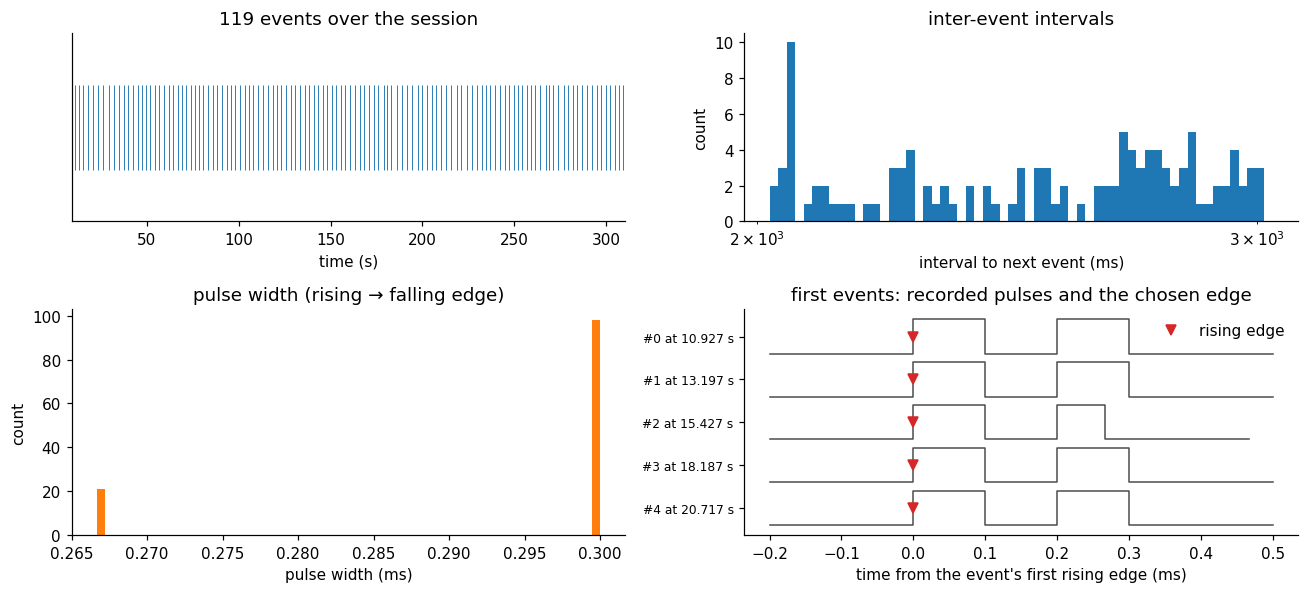

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 5.5), gridspec_kw={"height_ratios": [1, 1.2]})
a = ax[0, 0]
a.eventplot(event_t, lineoffsets=0, linelengths=0.8, linewidths=0.6, color="C0")
a.set_xlim(ts.t[0], ts.t[-1]); a.set_yticks([]); a.set_xlabel("time (s)")
a.set_title(f"{len(event_t)} events over the session")

a = ax[0, 1]
isi = np.diff(event_t) * 1000.0
if isi.size:
    a.hist(isi, bins=np.logspace(np.log10(max(isi.min(), 1e-2)), np.log10(isi.max() * 1.01), 60), color="C0")
    a.set_xscale("log")
a.set_xlabel("interval to next event (ms)"); a.set_ylabel("count"); a.set_title("inter-event intervals")

a = ax[1, 0]
a.hist(width_ms, bins=60, color="C1"); a.set_xlabel("pulse width (ms)"); a.set_ylabel("count")
a.set_title("pulse width (rising → falling edge)")

a = ax[1, 1]
raw = pulses_of(line)                                         # the line as recorded, before merging
for j, (start, end) in enumerate(pulses[:5]):
    near = raw[(raw[:, 1] >= start) & (raw[:, 0] <= end)]     # the recorded pulses this event holds
    pad = max(0.25 * (end - start), 0.2e-3)
    x = np.concatenate([[start - pad], np.repeat(near.ravel(), 2), [end + pad]])
    y = np.concatenate([[0], np.tile([0, 1, 1, 0], len(near)), [0]]) * 0.8 - j
    a.plot((x - start) * 1000.0, y, color="0.3", lw=1)
    a.plot((event_t[j] - start) * 1000.0, 0.4 - j, "v", color="C3", label=f"{EDGE} edge" if j == 0 else None)
a.set_yticks(-np.arange(min(5, len(pulses))) + 0.4, [f"#{j} at {t:.3f} s" for j, t in enumerate(pulses[:5, 0])], fontsize=8)
a.set_xlabel("time from the event's first rising edge (ms)")
a.legend(loc="upper right", frameon=False)
a.set_title("first events: recorded pulses and the chosen edge")
fig.tight_layout()

## 5. Cut the signal out around each event

For each event the sample nearest the aligned edge is found on the stream's time axis, and
`PRE_MS` before to `POST_MS` after is read with `ts.block` (µV, only those samples are read from
disk). With a band (`BAND = (low, high)` Hz, 0 on a side = open) every snippet is read with
`PAD_MS` extra on both sides, filtered forwards and backwards (Butterworth, zero phase), and the
padding cut off, so the filter's edge transients fall outside the window.

`NORM` is applied to every trial before averaging, so the mean, the SD band and the trials share a unit:
`"none"` (as recorded), `"baseline"` (minus the trial's mean over the `BASE_MS` before the event),
`"baseline_z"` (that, divided by the trial's SD over the same stretch).
Events too close to either end of the recording for a full window, or whose window spans samples
the acquisition dropped, are skipped.

In [8]:
CHANNEL = "A_CH5"          # the electrode the test pulse is recorded on
PRE_MS, POST_MS = 20.0, 50.0
BAND = None             # e.g. (1, 300) for LFP, (120, 200) for the ripple band, (300, 6000) for spikes
NORM = "baseline"       # "none" | "baseline" | "baseline_z"
BASE_MS = 10.0
PAD_MS = 200.0          # filter padding, only used with BAND
MAX_EVENTS = 2000       # evenly spread subset when there are more

fs = float(ts.fs)
n_pre, n_post = int(round(PRE_MS / 1000 * fs)), int(round(POST_MS / 1000 * fs))
t_ms = np.arange(-n_pre, n_post + 1) / fs * 1000.0

def make_filter(band, fs):
    if not band or not (band[0] or band[1]):
        return None
    lo, hi = band
    if lo and hi:
        return butter(4, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return butter(4, lo or hi, btype="highpass" if lo else "lowpass", fs=fs, output="sos")

def cut(ts, times, names, sos=None):
    """(n_events, n_channels, n_samples) snippets of `names` around `times`, and the events used."""
    pad = int(round(PAD_MS / 1000 * fs)) if sos is not None else 0
    centre = np.searchsorted(ts.t, times, "left")
    centre = np.where((centre > 0) & (np.abs(ts.t[np.maximum(centre - 1, 0)] - times) < np.abs(ts.t[np.minimum(centre, ts.n - 1)] - times)),
                      centre - 1, centre)                           # nearest sample, not just the next one
    lo, hi = centre - n_pre - pad, centre + n_post + 1 + pad
    ok = np.flatnonzero((lo >= 0) & (hi <= ts.n))
    span = ts.t[hi[ok] - 1] - ts.t[lo[ok]]
    ok = ok[np.abs(span - (hi[ok] - lo[ok] - 1) / fs) < 0.5 / fs]    # no dropped samples inside the window
    out = np.empty((ok.size, len(names), n_pre + n_post + 1), np.float32)
    for j, i in enumerate(ok):
        y = ts.block(int(lo[i]), int(hi[i]), names).T               # (channels, samples), physical units
        if sos is not None:
            y = sosfiltfilt(sos, y, axis=-1)[:, pad:y.shape[1] - pad]
        out[j] = y
    return out, ok

def normalise(x, norm=NORM):
    if norm == "none":
        return x
    nb = int(min(max(round(BASE_MS / 1000 * fs), 2), n_pre))
    base = x[..., n_pre - nb:n_pre]
    x = x - base.mean(-1, keepdims=True)
    return x / np.maximum(base.std(-1, keepdims=True), 1e-12) if norm == "baseline_z" else x

use = event_t if event_t.size <= MAX_EVENTS else event_t[np.unique(np.linspace(0, event_t.size - 1, MAX_EVENTS).round().astype(int))]
channel = CHANNEL or (electrodes or ts.names)[0]
sos = make_filter(BAND, fs)
trials, used = cut(ts, use, [channel], sos)
trials = normalise(trials[:, 0])
unit = {"baseline_z": "z (baseline)"}.get(NORM, ts.unit(channel))
print(f"{channel}: {len(used)} of {len(event_t)} events (the rest too near an end or across dropped samples), window -{PRE_MS:g}…+{POST_MS:g} ms, "
      f"band {BAND or 'as recorded'}, norm {NORM}, unit {unit}")

A_CH5: 119 of 119 events (the rest too near an end or across dropped samples), window -20…+50 ms, band as recorded, norm baseline, unit uV


### One channel: single trials, mean ± SD, and every trial as a row

The dotted lines mark the median interval to the neighbouring event: when events come in a regular
train, the response to the previous and next one shows up there, not as part of this one's response.

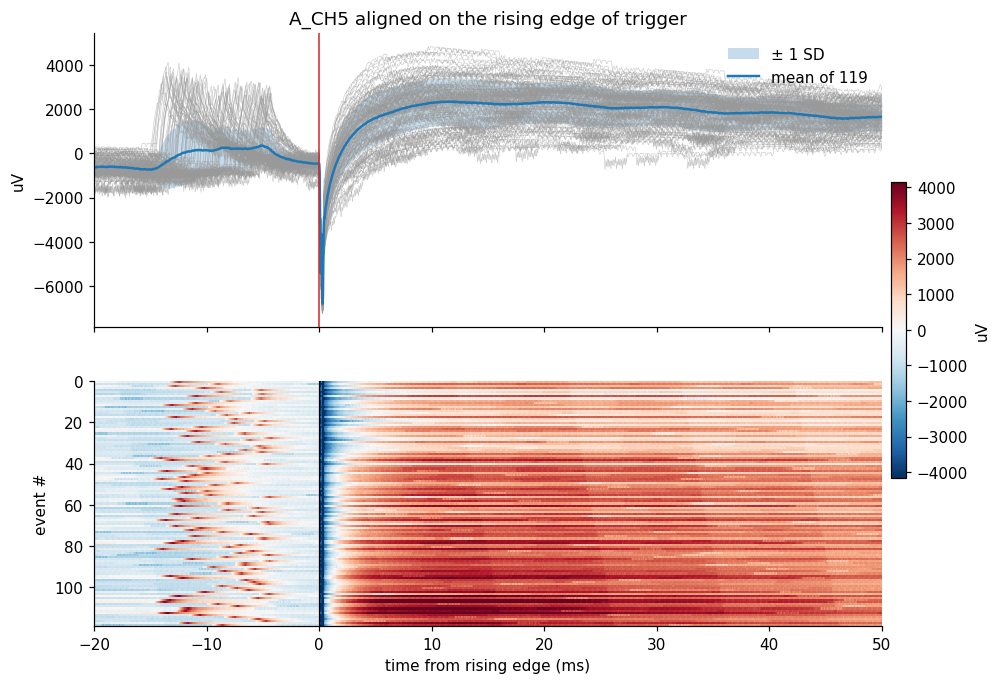

In [9]:
mean, sd = trials.mean(0), trials.std(0)
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
a = ax[0]
step = max(1, len(trials) // 100)
a.plot(t_ms, trials[::step].T, color="0.6", lw=0.4, alpha=0.5)
a.fill_between(t_ms, mean - sd, mean + sd, color="C0", alpha=0.25, lw=0, label="± 1 SD")
a.plot(t_ms, mean, color="C0", lw=1.6, label=f"mean of {len(trials)}")
a.axvline(0, color="C3", lw=1)
if isi.size:
    for s in (-1, 1):
        a.axvline(s * np.median(isi), color="0.3", ls=":", lw=1)
a.set_ylabel(unit); a.legend(frameon=False, loc="upper right")
a.set_title(f"{channel} aligned on the {EDGE} edge of {label(line)}")

a = ax[1]
lim = np.percentile(np.abs(trials), 99)
im = a.imshow(trials, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest",
              extent=[t_ms[0], t_ms[-1], len(trials), 0])
a.axvline(0, color="k", lw=0.8)
a.set_xlabel(f"time from {EDGE} edge (ms)"); a.set_ylabel("event #")
fig.colorbar(im, ax=ax, label=unit, shrink=0.5, pad=0.01)

### Every electrode: the average by depth

The same cut on all electrodes at once (one `ts.block` read per event), averaged per channel.
Lanes are in recorded order, which for these probes is depth order (tip first on the Poly2 via the
Channel Map), and share one vertical scale so amplitudes compare across depth.
Kept as running sums so a long train of events never needs all the trials in memory.

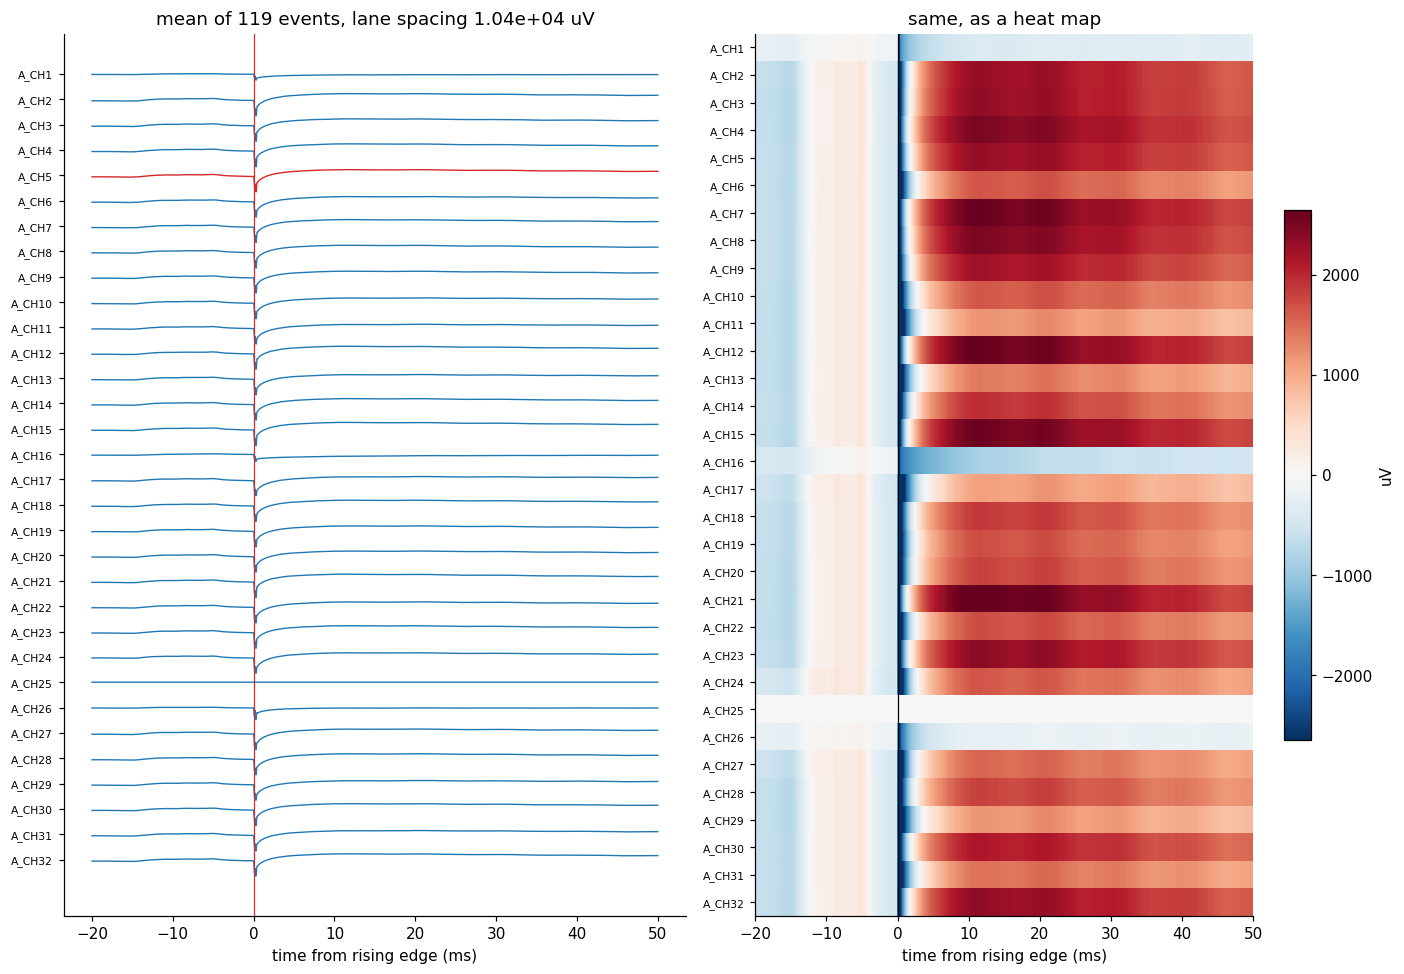

In [10]:
SCALE = None            # µV (or z) per lane spacing; None = from the data

def average_all(ts, times, names, sos=None, chunk=64):
    acc = acc2 = None; n = 0
    for k in range(0, len(times), chunk):
        x, ok = cut(ts, times[k:k + chunk], names, sos)
        if not len(ok):
            continue
        x = normalise(x).astype(np.float64)
        acc = x.sum(0) if acc is None else acc + x.sum(0)
        acc2 = (x ** 2).sum(0) if acc2 is None else acc2 + (x ** 2).sum(0)
        n += len(ok)
    m = acc / n
    return m, np.sqrt(np.maximum(acc2 / n - m ** 2, 0)), n

names = electrodes or ts.names
avg, avg_sd, n_avg = average_all(ts, use, names, sos)
gap = SCALE or float(np.median(np.ptp(avg, axis=1))) * 1.2 or 1.0

fig, ax = plt.subplots(1, 2, figsize=(13, max(5, 0.28 * len(names))), gridspec_kw={"width_ratios": [1, 1]})
a = ax[0]
for i, nm in enumerate(names):
    a.plot(t_ms, avg[i] - i * gap, color="C0" if nm != channel else "C3", lw=0.9)
a.set_yticks(-np.arange(len(names)) * gap, names, fontsize=7)
a.axvline(0, color="C3", lw=0.8)
a.set_xlabel(f"time from {EDGE} edge (ms)")
a.set_title(f"mean of {n_avg} events, lane spacing {gap:.3g} {unit}")

a = ax[1]
lim = np.percentile(np.abs(avg), 99) or 1.0
im = a.imshow(avg, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest",
              extent=[t_ms[0], t_ms[-1], len(names) - 0.5, -0.5])
a.set_yticks(range(len(names)), names, fontsize=7)
a.axvline(0, color="k", lw=0.8); a.set_xlabel(f"time from {EDGE} edge (ms)")
a.set_title("same, as a heat map")
fig.colorbar(im, ax=a, label=unit, shrink=0.6)
fig.tight_layout()

## 6. Latency from a reference TTL line

When one line is a trigger and this one marks what it caused (a detector firing, then the stimulus
reaching the tissue), the delay between them is the latency of the loop. Matching is **causal and
one-to-one**: each event is paired with the latest reference edge at or before it, no more than
`MAX_LAT_MS` earlier, and a reference edge is used at most once (by the first event after it).
Without the causal rule a pulse that happens to fall just before its trigger is matched too and the
mean stops meaning anything. `REF_LINE = None` skips this step.

OpenEphys detection time (rising) -> trigger (rising): 119 matched of 119 events and 119 reference edges
latency 7.055 ± 1.918 ms (mean ± SD), median 6.900, range 4.033–10.500 ms


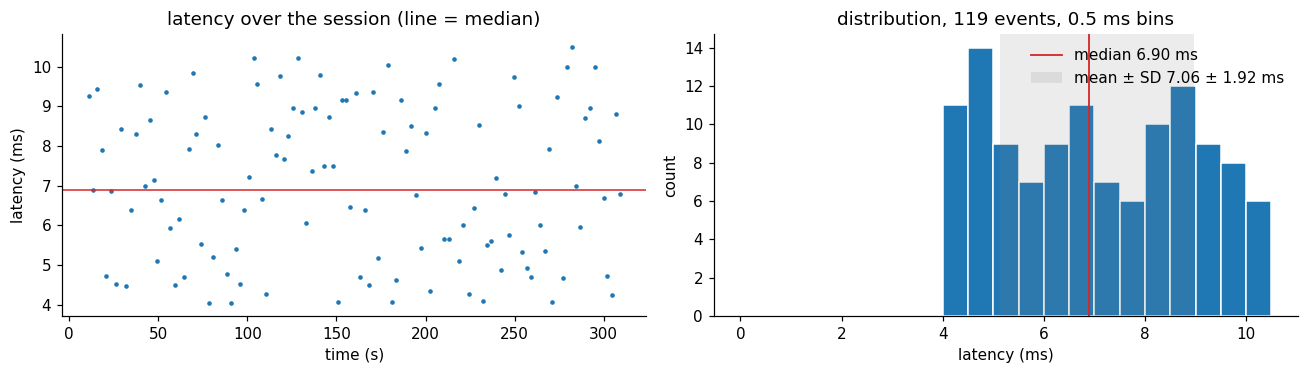

In [11]:
REF_LINE = 3            # Ripple Detector TTL8: the trigger
REF_EDGE = "rising"
REF_MERGE_MS = 0.0
MAX_LAT_MS = 50.0
LAT_BIN_MS = 0.5         # histogram bin width

if REF_LINE is not None:
    ref, _ = merge(pulses_of(lines[REF_LINE]), REF_MERGE_MS)
    ref_t = ref[:, 0] if REF_EDGE == "rising" else ref[:, 1]
    k = np.searchsorted(ref_t, event_t, "right") - 1            # latest reference edge at or before each event
    lat_ms = np.where(k >= 0, (event_t - ref_t[np.maximum(k, 0)]) * 1000.0, np.nan)
    ok = np.flatnonzero(np.isfinite(lat_ms) & (lat_ms <= MAX_LAT_MS))
    ok = ok[np.unique(k[ok], return_index=True)[1]]             # one event per reference edge: the first
    lat = lat_ms[ok]
    print(f"{label(lines[REF_LINE])} ({REF_EDGE}) -> {label(line)} ({EDGE}): "
          f"{lat.size} matched of {len(event_t)} events and {len(ref_t)} reference edges")
    print(f"latency {lat.mean():.3f} ± {lat.std():.3f} ms (mean ± SD), median {np.median(lat):.3f}, "
          f"range {lat.min():.3f}–{lat.max():.3f} ms")
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(event_t[ok], lat, ".", ms=4)
    ax[0].axhline(np.median(lat), color="C3", lw=1)
    ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("latency (ms)"); ax[0].set_title("latency over the session (line = median)")
    ax[1].hist(lat, bins=np.arange(0, lat.max() + LAT_BIN_MS, LAT_BIN_MS), color="C0", edgecolor="white", lw=0.5)
    ax[1].axvline(np.median(lat), color="C3", lw=1.2, label=f"median {np.median(lat):.2f} ms")
    ax[1].axvspan(lat.mean() - lat.std(), lat.mean() + lat.std(), color="0.5", alpha=0.15, lw=0,
                  label=f"mean ± SD {lat.mean():.2f} ± {lat.std():.2f} ms")
    ax[1].yaxis.get_major_locator().set_params(integer=True)
    ax[1].set_xlabel("latency (ms)"); ax[1].set_ylabel("count"); ax[1].legend(frameon=False, loc="upper right")
    ax[1].set_title(f"distribution, {lat.size} events, {LAT_BIN_MS:g} ms bins")
    fig.tight_layout()

## 7. Raw traces aligned on the reference line

The matched pairs of step 6, seen in the signal. Each trace is one trial of one channel as recorded
(only its mean over the `RAW_PRE_MS` before the reference edge removed, so traces overlap), all
matched trials overlaid in one partly transparent colour, so where many trials agree the colour
builds up and a single odd trial stays faint. Left: cut around the **reference** edge — whatever
the event caused is smeared by the latency jitter. Right: the same trials cut around the **event**
edge — if the response collapses onto one shape here, it follows the event, not the reference.

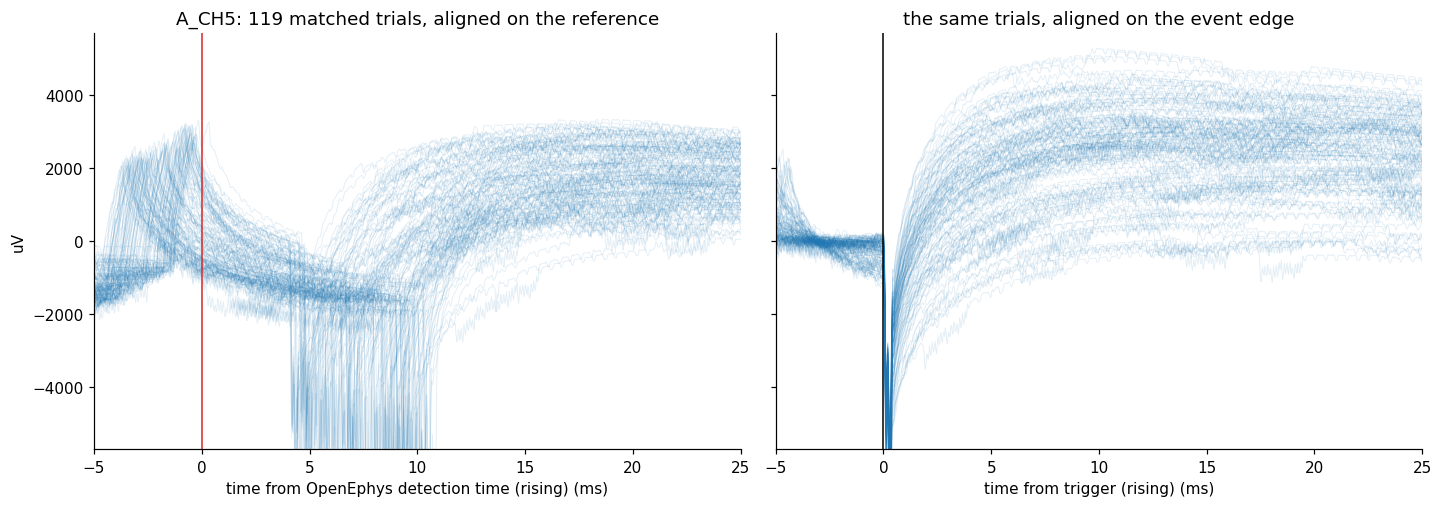

In [12]:
RAW_CHANNEL = None              # None = the channel of step 5
RAW_PRE_MS, RAW_POST_MS = 5.0, 25.0
RAW_ALPHA = 0.12                # ~120 trials

if REF_LINE is not None:
    ch = RAW_CHANNEL or channel
    r0, r1 = int(round(RAW_PRE_MS / 1000 * fs)), int(round(RAW_POST_MS / 1000 * fs))
    raw_ms = np.arange(-r0, r1 + 1) / fs * 1000.0

    def raw_trials(centres):
        """One channel, as recorded, around each time; minus its mean over the RAW_PRE_MS before it."""
        idx = np.searchsorted(ts.t, centres, "left")
        out = np.full((len(centres), r0 + r1 + 1), np.nan)
        for j, i in enumerate(idx):
            if i - r0 >= 0 and i + r1 + 1 <= ts.n and abs(ts.t[i + r1] - ts.t[i - r0] - (r0 + r1) / fs) < 0.5 / fs:
                y = ts.block(int(i - r0), int(i + r1 + 1), [ch])[:, 0]
                out[j] = y - y[:r0].mean()
        return out

    ref_of = ref_t[k[ok]]                                     # reference edge of each matched event
    on_ref, on_evt = raw_trials(ref_of), raw_trials(event_t[ok])
    lim = np.nanpercentile(np.abs(on_ref), 99.5)

    fig, (a_ref, a_evt) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, layout="constrained")
    a_ref.plot(raw_ms, on_ref.T, color="C0", lw=0.6, alpha=RAW_ALPHA)
    a_evt.plot(raw_ms, on_evt.T, color="C0", lw=0.6, alpha=RAW_ALPHA)
    a_ref.axvline(0, color="C3", lw=1)
    a_evt.axvline(0, color="k", lw=1)
    for a, what in ((a_ref, f"{label(lines[REF_LINE])} ({REF_EDGE})"), (a_evt, f"{label(line)} ({EDGE})")):
        a.set_xlim(raw_ms[0], raw_ms[-1]); a.set_ylim(-lim, lim)
        a.set_xlabel(f"time from {what} (ms)")
    a_ref.set_ylabel(ts.unit(ch))
    a_ref.set_title(f"{ch}: {int(np.isfinite(on_ref[:, 0]).sum())} matched trials, aligned on the reference")
    a_evt.set_title("the same trials, aligned on the event edge")

## 8. The full chain: digital input → electrode → OpenEphys detection time → trigger

The audio test signal was also fed to the headstage's GPIO 6, so the **digital input** (`TTL6`) marks when
the test pulse was produced. That splits the loop into stages, each matched causally and one-to-one as in
step 6: **digital input → OpenEphys detection time** (`TTL8`, how long the Ripple Detector took to fire on
the signal), **OpenEphys detection time → trigger** (`TTL2`, the wait for the stimulator's trigger) and
their sum, **digital input → trigger**, the whole loop. All TTL times are on the broadband stream's clock.


119 digital input pulses, 119 detections, 119 triggers
digital input → OpenEphys detection time    119 matched: 2.909 ± 1.091 ms, median 2.900, range 0.667–4.800
OpenEphys detection time → trigger          119 matched: 7.055 ± 1.918 ms, median 6.900, range 4.033–10.500
digital input → trigger                     119 matched: 9.965 ± 2.993 ms, median 9.900, range 5.267–15.033


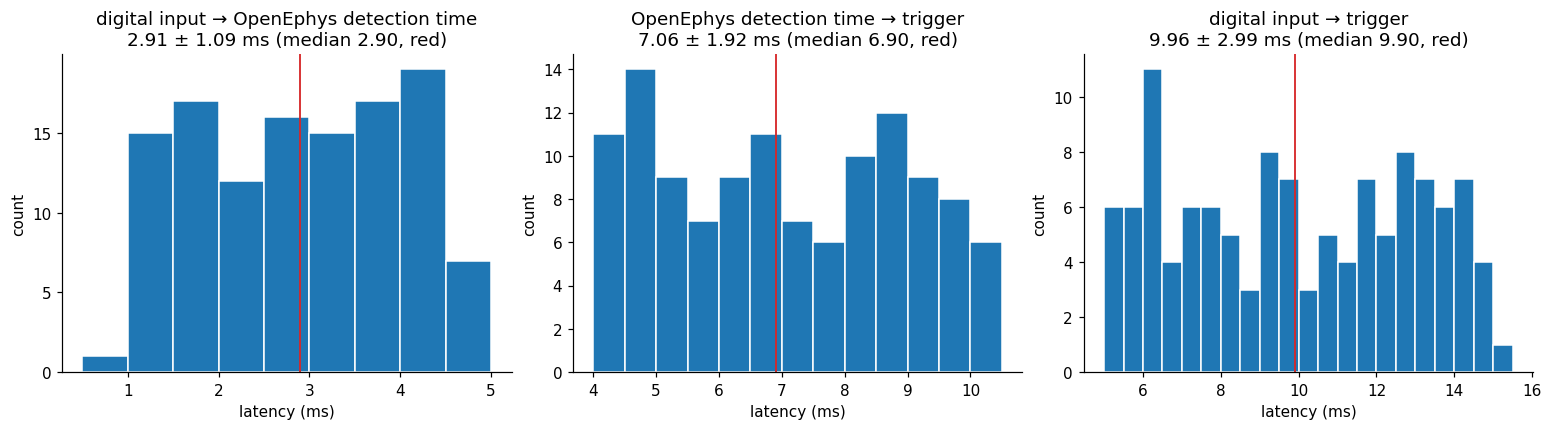

In [13]:
AUDIO_LINE, TRIG_LINE, STIM_LINE = 2, 3, 0     # indices in the TTL list of step 3: TTL6, Ripple Detector TTL8, TTL2
STIM_MERGE_MS = 1.0

def follow(ref_t, ev_t, max_ms=MAX_LAT_MS):
    """Latency (ms) of the first event after each reference edge, NaN where none follows within max_ms."""
    k = np.searchsorted(ref_t, ev_t, "right") - 1
    lat = np.full(ref_t.size, np.nan)
    for j in np.flatnonzero(k >= 0)[::-1]:             # reversed, so the first event after a reference wins
        d = (ev_t[j] - ref_t[k[j]]) * 1000.0
        if d <= max_ms:
            lat[k[j]] = d
    return lat

audio_t = pulses_of(lines[AUDIO_LINE])[:, 0]
trig_t = pulses_of(lines[TRIG_LINE])[:, 0]
stim_t = merge(pulses_of(lines[STIM_LINE]), STIM_MERGE_MS)[0][:, 0]
a2t = follow(audio_t, trig_t)
t2s = follow(trig_t, stim_t)
a2s = follow(audio_t, stim_t)
DIN, DET, TRG = "digital input", "OpenEphys detection time", "trigger"
stages = [(f"{DIN} → {DET}", a2t), (f"{DET} → {TRG}", t2s), (f"{DIN} → {TRG}", a2s)]
print(f"{audio_t.size} {DIN} pulses, {trig_t.size} detections, {stim_t.size} {TRG}s")
for name, d in stages:
    v = d[np.isfinite(d)]
    print(f"{name:42s} {v.size:4d} matched: {v.mean():.3f} ± {v.std():.3f} ms, median {np.median(v):.3f}, range {v.min():.3f}–{v.max():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
for a, (name, d) in zip(ax, stages):
    v = d[np.isfinite(d)]
    bw = 0.05 if np.ptp(v) < 3 else LAT_BIN_MS
    a.hist(v, bins=np.arange(np.floor(v.min() / bw) * bw, v.max() + bw, bw), color="C0", edgecolor="white", lw=0.5)
    a.axvline(np.median(v), color="C3", lw=1.2)
    a.yaxis.get_major_locator().set_params(integer=True)
    a.set_title(f"{name}\n{v.mean():.2f} ± {v.std():.2f} ms (median {np.median(v):.2f}, red)")
    a.set_xlabel("latency (ms)"); a.set_ylabel("count")


### What the detector saw

The detector's input channel cut out around each **digital input** edge, every trial overlaid, with the
**OpenEphys detection time** marked on each trace. When the detector reads the LFP stream, its input is taken from
that stream (`IN_STREAM`), on that stream's own time axis — treat the LFP trace's timing as approximate:
detections can precede the recorded LFP rise, so the LFP timestamps lag what the detector processed. Right:
the detection time against that trial's pulse peak.


LFP_A_CH5: median pulse peaks at 3435 uV, 5.000 ms after the digital input edge; reaches 10 % of that at 4.000 ms, 50 % at 4.333 ms
the OpenEphys detection time fell at 104 uV (median; 5–95 %: -417–1893)


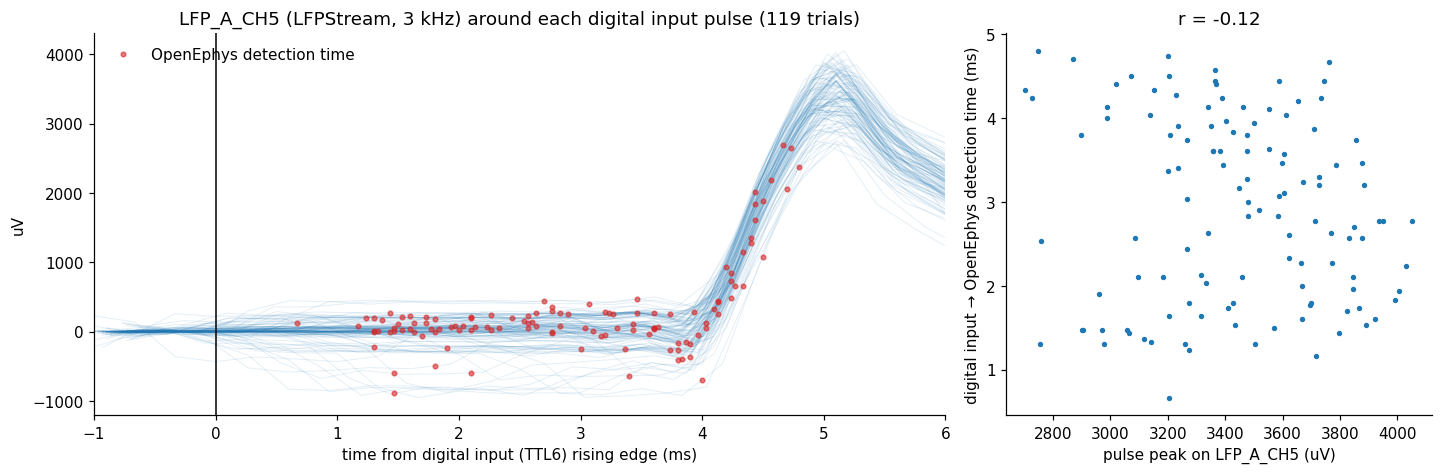

In [14]:
IN_STREAM = "LFPStream"
IN_CHANNEL = "LFP_A_CH5"        # the Ripple Detector's input (ripple_input = 40 = LFP channel 5)
IN_PRE_MS, IN_POST_MS = 1.0, 6.0

src = ts if IN_STREAM in (None, ts.stream) else dio.load(rec["path"], stream=IN_STREAM)
sfs = float(src.fs)
w0, w1 = int(round(IN_PRE_MS / 1000 * sfs)), int(round(IN_POST_MS / 1000 * sfs))
win_ms = np.arange(-w0, w1 + 1) / sfs * 1000.0
idx = np.searchsorted(src.t, audio_t, "left")
ok_a = np.flatnonzero((idx - w0 >= 0) & (idx + w1 + 1 <= src.n) & np.isfinite(a2t))
X = np.array([src.block(int(i - w0), int(i + w1 + 1), [IN_CHANNEL])[:, 0] for i in idx[ok_a]])
X -= X[:, :max(w0, 1)].mean(1, keepdims=True)
X_ms = win_ms[None, :] + (src.t[idx[ok_a]] - audio_t[ok_a])[:, None] * 1000.0   # each trial on its own sample times
peak = X[:, w0:].max(1)
fire = a2t[ok_a]
y_fire = np.array([np.interp(f, xm, x) for f, xm, x in zip(fire, X_ms, X)])

fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained", gridspec_kw={"width_ratios": [2, 1]})
for xm, x in zip(X_ms, X):
    a0.plot(xm, x, color="C0", lw=0.6, alpha=RAW_ALPHA)
a0.plot(fire, y_fire, "o", color="C3", ms=3, alpha=0.6, label=DET)
a0.axvline(0, color="k", lw=1)
a0.set_xlim(-IN_PRE_MS, IN_POST_MS)
a0.set_xlabel(f"time from {DIN} (TTL6) rising edge (ms)"); a0.set_ylabel(src.unit(IN_CHANNEL))
a0.set_title(f"{IN_CHANNEL} ({src.stream}, {sfs / 1000:g} kHz) around each {DIN} pulse ({len(ok_a)} trials)")
a0.legend(frameon=False, loc="upper left")
a1.plot(peak, fire, ".", ms=5)
a1.set_xlabel(f"pulse peak on {IN_CHANNEL} ({src.unit(IN_CHANNEL)})"); a1.set_ylabel(f"{DIN} → {DET} (ms)")
a1.set_title(f"r = {np.corrcoef(peak, fire)[0, 1]:.2f}")
m = np.median(X, 0)
print(f"{IN_CHANNEL}: median pulse peaks at {m.max():.0f} {src.unit(IN_CHANNEL)}, {win_ms[m.argmax()]:.3f} ms after the {DIN} edge; "
      f"reaches 10 % of that at {win_ms[np.argmax(m > 0.1 * m.max())]:.3f} ms, 50 % at {win_ms[np.argmax(m > 0.5 * m.max())]:.3f} ms")
print(f"the {DET} fell at {np.median(y_fire):.0f} {src.unit(IN_CHANNEL)} (median; 5–95 %: "
      f"{np.percentile(y_fire, 5):.0f}–{np.percentile(y_fire, 95):.0f})")


## Check against the app

The viewer's triggered average (`dataanalyzer.triggered`) on the same line, edge, window, band and
normalisation. Its event set is built from the same TTL line; `start` is the rising edge and `end`
the falling one. Small differences are expected from the filter (the app uses its own band-pass
and padding) and from the app taking the next sample at or after the edge rather than the nearest.

app: 119 events, notebook: 119 events; correlation of the means r = 1.0000, max |difference| = 1.88 uV (mean peak-to-peak 9.14e+03)


Text(0, 0.5, 'uV')

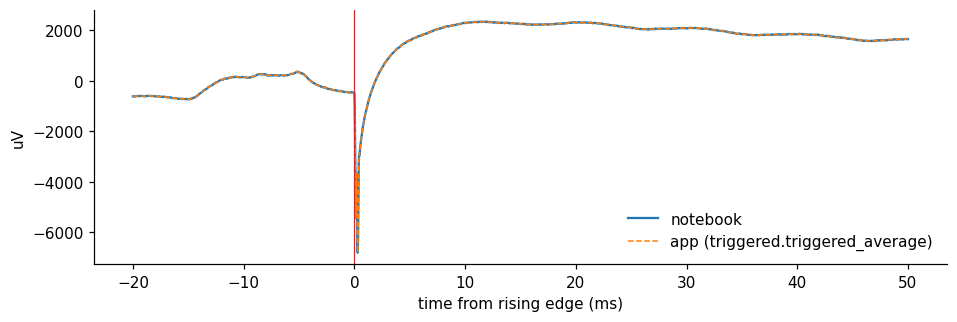

In [15]:
from dataanalyzer import detect, triggered

sets = detect.online_detections(ts, merge_ms=MERGE_MS)
name = next(k for k, v in sets.items() if v["line"] == line["line"] and (v["stream"] or ts.stream) == (line["stream"] or ts.stream))
app_set = sets[name]
if T_RANGE is not None:
    app_set = dict(app_set, events=[e for e in app_set["events"] if e["start"] >= T_RANGE[0] and e["end"] <= T_RANGE[1]])
app = triggered.triggered_average(ts, app_set, channel, pre_ms=PRE_MS, post_ms=POST_MS,
                                  align="start" if EDGE == "rising" else "end", band=BAND, norm=NORM,
                                  base_ms=BASE_MS, max_average=MAX_EVENTS, max_points=10**7)
app_t, app_mean = np.asarray(app["t_ms"]), np.asarray(app["mean"])
mine = np.interp(app_t, t_ms, mean)
r = np.corrcoef(mine, app_mean)[0, 1]
print(f"app: {app['n_averaged']} events, notebook: {len(trials)} events; correlation of the means r = {r:.4f}, "
      f"max |difference| = {np.max(np.abs(mine - app_mean)):.3g} {unit} (mean peak-to-peak {np.ptp(mean):.3g})")
plt.figure(figsize=(10, 3))
plt.plot(t_ms, mean, label="notebook", lw=1.5)
plt.plot(app_t, app_mean, "--", label="app (triggered.triggered_average)", lw=1)
plt.axvline(0, color="C3", lw=0.8); plt.legend(frameon=False); plt.xlabel(f"time from {EDGE} edge (ms)"); plt.ylabel(unit)